# Лабораторна робота № 1

## Вхідний аналіз набору даних

**Дисципліна:** Інтелектуальний аналіз та візуалізація даних (СК26)
**Тривалість:** 2 год аудиторно + 3 год самостійної роботи · **Максимальна оцінка:** 4 бали

---

### Мета роботи

Пригадати роботу в Jupyter Notebook, бібліотеці `pandas` та побудову графіків —
і зробити це не на навчальному прикладі, а на реальному файлі, який ніхто не готував
спеціально для вас.

Ця робота виконується **до першої лекції**. Нічого нового знати не потрібно: усе,
що знадобиться, ви вже проходили в попередніх курсах. Усі поняття, яких ви тут
торкнетеся мимохідь, отримають назви й пояснення на лекціях 3 і 4.

### Дані

Файл `20171129_FINAL_FINAL.xlsx`, аркуш `Sheet1` — спостереження космічної погоди
за 28 серпня — 22 вересня 2017 року, зібрані з трьох різних джерел.

Файл видається **як є**, рівно в тому вигляді, у якому його колись вивантажили.
Ніхто не приводив його до ладу, і саме в цьому сенс: справжні дані здебільшого
надходять саме такими.

### Що ви маєте зробити

| Етап | Зміст | Де |
|---|---|---|
| 1 | Розібратися, що взагалі лежить у файлі | аудиторно |
| 2 | Виділити три таблиці й привести їх до робочого вигляду | аудиторно |
| 3 | Скласти паспорт даних: що є, чого бракує, що виглядає дивно | аудиторно |
| 4 | Об'єднати три таблиці в одну | аудиторно |
| 5 | Побудувати п'ять графіків, кожен — відповідь на питання | аудиторно + самостійно |
| 6 | Порівняти два графіки одних і тих самих даних | самостійно |
| 7 | Записати три спостереження про дані | самостійно |
| 8 | Декларація про використання інструментів ШІ | самостійно |

### Що здається

1. Цей файл `.ipynb` із заповненими розв'язками. **Ноутбук має виконуватися згори
   донизу на чистому ядрі** (Kernel → Restart & Run All) без помилок — це перевіряється
   першою дією на захисті.
2. Файл `master_hourly.csv` — об'єднана таблиця з етапу 4.
3. Експорт ноутбука у HTML або PDF.
4. Заповнена декларація (етап 8). Без неї фінальна самоперевірка не проходить.

### Критерії оцінювання

| Бали | Що досягнуто |
|---|---|
| 0 | Дані не опрацьовано, графіки не побудовано або побудовано з грубими помилками |
| 1 | Таблиці прочитано й кілька графіків побудовано, але типи графіків не відповідають даним, дивних значень не помічено |
| 2 | Таблиці розібрано й об'єднано, графіки коректні та підписані, але висновків під ними немає або вони формальні |
| 4 | Усе вище виконано, знайдено й пояснено дивні значення, під кожним графіком є змістовний висновок про дані |

**Головне про оцінку:** бали ставляться не за наявність графіка, а за речення під ним.
Код, який нічого не пояснює, коштує двох балів з чотирьох.

---
## Нагадування про Jupyter

Якщо давно не працювали — три речі, які знадобляться сьогодні:

* `Shift+Enter` виконує клітинку, `Esc` `A` / `Esc` `B` додає клітинку вище / нижче,
  `Esc` `M` перетворює клітинку на текстову (Markdown), `Esc` `Y` — назад на код.
* **Порядок виконання має значення.** Якщо ви правили клітинки в довільному порядку,
  результат може залежати від історії запусків. Перед здачею обов'язково
  **Kernel → Restart & Run All** — так ви побачите ноутбук очима викладача.
* Текстові клітинки — не прикраса. Висновки пишуться в них, а не в коментарях до коду.

---
## Крок 0. Ваші дані та варіант

Заповніть три змінні й виконайте обидві клітинки. Друга надрукує **ваше
індивідуальне завдання** — воно відрізняється від завдання сусіда.

In [62]:
ПІБ = 'Бобринок Ангеліна Вадимівна'
ГРУПА = 'ШІ-32'
ВАРІАНТ = 3            # ваш номер за списком групи

assert ПІБ and ГРУПА and ВАРІАНТ, 'Заповніть ПІБ, ГРУПУ та ВАРІАНТ'

In [63]:
# --- клітинку не редагувати: вона видає ваше персональне завдання ------------
ПОТОКИ = ['P>1', 'P>5', 'P>10', 'P>30', 'P>50', 'P>100', 'E>0.8', 'E>2.0']

ПАРИ = [('швидкість вітру', 'густина вітру'),
        ('швидкість вітру', 'потік P>10'),
        ('густина вітру', 'потік P>1'),
        ('радіопотік F10.7', 'потік P>10'),
        ('радіопотік F10.7', 'швидкість вітру'),
        ('потік E>0.8', 'потік P>10')]

АГРЕГАТИ = ['середнє', 'максимум', 'медіана', 'мінімум']

ПИТАННЯ = [
    'Скільки годин за все вікно ваш потік перевищував своє власне медіанне значення?',
    'У яку добу середнє значення вашого потоку було найбільшим? А найменшим?',
    'О котрій годині доби потік E>0.8 у середньому найбільший? Побудуйте графік середнього за годинами доби.',
    'Яка частка рядків об’єднаної таблиці має пропуск хоча б в одному стовпці?',
    'У який день радіопотік F10.7 був найбільшим і чи збігається цей день з піком вашого потоку?',
    'Порівняйте медіану вашого потоку за перший і за другий тиждень спостережень. У скільки разів вони відрізняються?',
    'Скільки годин поспіль тривала найдовша неперервна серія «активних» годин (група з етапу 4)?',
    'Який зі стовпців об’єднаної таблиці має найбільший розкид відносно власного середнього?',
    'Яку частку сумарного значення вашого потоку за все вікно дали 24 години навколо піку?',
    'Скільки різних діб потрапило у групу «активні» і скільки — у групу «дуже активні»?',
]

i = int(ВАРІАНТ)
завдання = {
    'ваш потік':                      ПОТОКИ[(i * 3 + 1) % 8],
    'ваша пара для графіка 3':        ' та '.join(ПАРИ[(i * 5 + 2) % 6]),
    'ваш агрегат для етапу 4':        АГРЕГАТИ[(i * 5 + 1) % 4],
    'ваше додаткове питання':         ПИТАННЯ[(i * 11 + 5) % 10],
}

print('ІНДИВІДУАЛЬНЕ ЗАВДАННЯ · %s, %s, варіант %d' % (ПІБ, ГРУПА, i))
print('=' * 78)
for k, v in завдання.items():
    print('%-28s %s' % (k + ':', v))

ІНДИВІДУАЛЬНЕ ЗАВДАННЯ · Бобринок Ангеліна Вадимівна, ШІ-32, варіант 3
ваш потік:                   P>10
ваша пара для графіка 3:     потік E>0.8 та потік P>10
ваш агрегат для етапу 4:     середнє
ваше додаткове питання:      Яку частку сумарного значення вашого потоку за все вікно дали 24 години навколо піку?


Далі за текстом **«ваш потік»** означає стовпець, названий у першому рядку завдання.

In [64]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 9})

ФАЙЛ = '20171129_FINAL_FINAL.xlsx'

---
# Етап 1. Що взагалі лежить у файлі

Перше правило роботи з незнайомими даними: спершу подивитися, потім рахувати.

### Завдання 1.1
Спробуйте прочитати аркуш `Sheet1` звичайним способом — `pd.read_excel(ФАЙЛ)` —
і виведіть перші рядки та типи стовпців.

*Очікуваний результат: результат буде дивним. Подивіться на назви стовпців і на
те, які там типи даних. Поясніть у наступній клітинці, чому так вийшло.*

In [65]:
спроба = pd.read_excel(ФАЙЛ)

print('розмір:', спроба.shape)
print()
print('назви стовпців:')
for назва in спроба.columns:
    print('   ', repr(назва))
print()
print('типи стовпців:')
print(спроба.dtypes.to_string())
print()
display(спроба.head(10))

розмір: (7225, 32)

назви стовпців:
    'Unnamed: 0'
    'ftp://ftp.swpc.noaa.gov/pub/lists/particle/'
    'Unnamed: 2'
    'Unnamed: 3'
    'Unnamed: 4'
    'Unnamed: 5'
    'Unnamed: 6'
    'Unnamed: 7'
    'Unnamed: 8'
    'Unnamed: 9'
    'Unnamed: 10'
    'Unnamed: 11'
    'Unnamed: 12'
    'Unnamed: 13'
    'Unnamed: 14'
    'Unnamed: 15'
    'Unnamed: 16'
    'Unnamed: 17'
    'Unnamed: 18'
    'Unnamed: 19'
    'Unnamed: 20'
    'Unnamed: 21'
    'Unnamed: 22'
    'Unnamed: 23'
    'Unnamed: 24'
    'Unnamed: 25'
    'http://umtof.umd.edu/pm/crn/'
    'Unnamed: 27'
    'Unnamed: 28'
    'Unnamed: 29'
    'Unnamed: 30'
    'Unnamed: 31'

типи стовпців:
Unnamed: 0                                     float64
ftp://ftp.swpc.noaa.gov/pub/lists/particle/     object
Unnamed: 2                                      object
Unnamed: 3                                      object
Unnamed: 4                                      object
Unnamed: 5                                      object
Un

,Unnamed: 0,ftp://ftp.swpc.noaa.gov/pub/lists/particle/,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16,Unnamed: 17,Unnamed: 18,Unnamed: 19,Unnamed: 20,Unnamed: 21,Unnamed: 22,Unnamed: 23,Unnamed: 24,Unnamed: 25,http://umtof.umd.edu/pm/crn/,Unnamed: 27,Unnamed: 28,Unnamed: 29,Unnamed: 30,Unnamed: 31
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,:Data_list: 20170901_Gs_part_5m.txt,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,SOHO CELIAS Proton Monitor,NaN,NaN,NaN,NaN,NaN
2,NaN,:Created: 2017 Sep 02 0011 UTC,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Solar Wind Parameters for Carrington Rotation ...,NaN,NaN,NaN,NaN,NaN
3,NaN,"# Prepared by the U.S. Dept. of Commerce, NOAA...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Proton speed [km/sec],NaN,NaN,NaN,NaN,NaN
4,NaN,# Please send comments and suggestions to SWPC...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Proton density [protons per cubic centimeter],NaN,NaN,NaN,NaN,NaN
5,NaN,#,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,# Label: P > 1 = Particles at >1 Mev,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"Measurement time (Year, Month, Day of Month, D...",NaN,NaN,NaN,NaN,NaN
7,NaN,# Label: P > 5 = Particles at >5 Mev,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,NaN,# Label: P >10 = Particles at >10 Mev,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,NaN,# Label: P >30 = Particles at >30 Mev,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Відповідь 1.1:** 

`pd.read_excel` за замовчуванням вважає **перший рядок аркуша заголовком**. Але в цьому
файлі перший рядок — не назви стовпців, а посилання на джерела
(`ftp://ftp.swpc.noaa.gov/pub/lists/particle/` і `http://umtof.umd.edu/pm/crn/`).
Тому:

* один стовпець отримав назву-URL, решта — автозгенеровані `Unnamed: 1`, `Unnamed: 2` тощо;
* під цим «заголовком» лежать ще ~25 рядків службового тексту (`# Label: ...`,
  `# Units: ...`, `# Source: GOES-15`), і аж потім числа. Оскільки в одному стовпці
  опинилися і текст, і числа, pandas змушений дати всьому стовпцю тип **`object`**,
  а не `float64`;
* справжні назви стовпців (`P > 1`, `P >10`, `SPEED`, `DENSITY`, …) залишилися десь
  усередині таблиці як звичайні дані.


### Завдання 1.2
Прочитайте аркуш ще раз, але **без заголовка**: `pd.read_excel(ФАЙЛ, header=None)`.
Виведіть його розмір і подивіться на перші 30 рядків.

In [66]:
RAW = pd.read_excel(ФАЙЛ, sheet_name='Sheet1', header=None)

print('розмір аркуша:', RAW.shape, '— %d рядків, %d стовпців' % RAW.shape)
display(RAW.head(30))

розмір аркуша: (7226, 32) — 7226 рядків, 32 стовпців


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31
0,NaN,ftp://ftp.swpc.noaa.gov/pub/lists/particle/,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,http://umtof.umd.edu/pm/crn/,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,:Data_list: 20170901_Gs_part_5m.txt,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,SOHO CELIAS Proton Monitor,NaN,NaN,NaN,NaN,NaN
3,NaN,:Created: 2017 Sep 02 0011 UTC,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Solar Wind Parameters for Carrington Rotation ...,NaN,NaN,NaN,NaN,NaN
4,NaN,"# Prepared by the U.S. Dept. of Commerce, NOAA...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Proton speed [km/sec],NaN,NaN,NaN,NaN,NaN
5,NaN,# Please send comments and suggestions to SWPC...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Proton density [protons per cubic centimeter],NaN,NaN,NaN,NaN,NaN
6,NaN,#,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,# Label: P > 1 = Particles at >1 Mev,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"Measurement time (Year, Month, Day of Month, D...",NaN,NaN,NaN,NaN,NaN
8,NaN,# Label: P > 5 = Particles at >5 Mev,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,NaN,# Label: P >10 = Particles at >10 Mev,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Завдання 1.3
Для кожного стовпця порахуйте, скільки в ньому заповнених клітинок
(`RAW.notna().sum()`), і виведіть результат.

*Очікуваний результат: 32 числа. Серед них будуть нулі та згустки великих значень.
За цими згустками видно, що в аркуші **не одна таблиця, а кілька**, вставлені поруч.*

**Питання:** скільки таблиць в аркуші і які стовпці займає кожна?

In [67]:
заповненість = RAW.notna().sum()
заповненість.index = ['%2d (%s)' % (i, chr(ord('A') + i) if i < 26 else 'A' + chr(ord('A') + i - 26))
                      for i in заповненість.index]
print('Скільки заповнених клітинок у кожному зі стовпців аркуша:')
print(заповненість.to_string())
print()
print('усього стовпців:', len(заповненість))
print('порожніх стовпців:', int((заповненість == 0).sum()))

Скільки заповнених клітинок у кожному зі стовпців аркуша:
 0 (A)        0
 1 (B)     7223
 2 (C)     7202
 3 (D)     7202
 4 (E)     7202
 5 (F)     7203
 6 (G)     7203
 7 (H)     7198
 8 (I)     7198
 9 (J)     7198
10 (K)     7198
11 (L)     7198
12 (M)     7198
13 (N)     7198
14 (O)     7198
15 (P)        0
16 (Q)       32
17 (R)       26
18 (S)       26
19 (T)       26
20 (U)        0
21 (V)        0
22 (W)        0
23 (X)        0
24 (Y)      601
25 (Z)      601
26 (AA)     608
27 (AB)     602
28 (AC)     602
29 (AD)     602
30 (AE)     602
31 (AF)     602

усього стовпців: 32
порожніх стовпців: 6


**Відповідь 1.3:**

Заповненість іде трьома «згустками», розділеними повністю порожніми стовпцями
(0, 15, 20–23). Це і є межі таблиць — **таблиць три**:

| Таблиця | Номери стовпців | Літери Excel | Заповненість | Що це |
|---|---|---|---|---|
| **A** | 1–14 | B–O | ~7200 | GOES-15, потоки частинок, крок 5 хв |
| **B** | 16–19 | Q–T | ~26 | добовий радіопотік F10.7 |
| **C** | 24–31 | Y–AF | ~601–608 | сонячний вітер, крок 1 година |

Три різні порядки заповненості (7200 / 26 / 601) — це три різні кроки в часі за той
самий період: 5 хвилин, доба і година.

Окремо: стовпці **24–25 (Y–Z)** містять не вимірювання, а продубльований лічильник
години 0…23 — службовий індекс вивантаження. Реальні дані таблиці C починаються
зі стовпця 26 (AA).

### Завдання 1.4
Над кожною таблицею є кілька текстових рядків — це службовий опис від тих, хто дані
збирав. Виведіть їх і випишіть для кожної таблиці **джерело даних та одиниці
вимірювання**.

*Це найкорисніші п'ять хвилин роботи: жодної з цих відомостей у самій таблиці немає,
і без них ви не знатимете, у чому вимірюєте.*

In [68]:
print('=' * 100)
for r in range(RAW.shape[0]):
    for c in range(RAW.shape[1]):
        v = RAW.iat[r, c]
        if isinstance(v, str):
            print('рядок %4d, стовпець %2d : %s' % (r, c, v))
print('=' * 100)

рядок    0, стовпець  1 : ftp://ftp.swpc.noaa.gov/pub/lists/particle/
рядок    0, стовпець 26 : http://umtof.umd.edu/pm/crn/
рядок    2, стовпець  1 : :Data_list: 20170901_Gs_part_5m.txt
рядок    2, стовпець 26 : SOHO CELIAS Proton Monitor
рядок    3, стовпець  1 : :Created: 2017 Sep 02 0011 UTC
рядок    3, стовпець 26 : Solar Wind Parameters for Carrington Rotation (hour averages)
рядок    4, стовпець  1 : # Prepared by the U.S. Dept. of Commerce, NOAA, Space Weather Prediction Center
рядок    4, стовпець 26 : Proton speed [km/sec]
рядок    5, стовпець  1 : # Please send comments and suggestions to SWPC.Webmaster@noaa.gov 
рядок    5, стовпець 26 : Proton density [protons per cubic centimeter]
рядок    6, стовпець  1 : # 
рядок    7, стовпець  1 : # Label: P > 1 = Particles at >1 Mev
рядок    7, стовпець 26 : Measurement time (Year, Month, Day of Month, Day of Year, Hour, Minute, Second)
рядок    8, стовпець  1 : # Label: P > 5 = Particles at >5 Mev
рядок    9, стовпець  1 : # Label: 

**Відповідь 1.4:**

| Таблиця | Джерело | Одиниці вимірювання |
|---|---|---|
| A | GOES-15 (W135), NOAA / SWPC, файл `20170901_Gs_part_5m.txt`, ftp://ftp.swpc.noaa.gov/pub/lists/particle/ | протони — `Protons/cm2-s-sr`, електрони — `Electrons/cm2-s-sr`; маркер пропуску `-1.00e+05` |
| B | NOAA / SWPC, Quarterly Daily Solar Data (`quar_DSD.txt`), ftp://ftp.swpc.noaa.gov/pub/indices/old_indices/2017Q3_DSD.txt | радіопотік F10.7 у s.f.u. (10⁻²² Вт·м⁻²·Гц⁻¹) — у файлі підписано лише «Radio Flux 10.7» |
| C | SOHO CELIAS Proton Monitor, http://umtof.umd.edu/pm/crn/ | швидкість — `km/sec`, густина — `protons per cubic centimeter` |

Дві речі, яких немає в самих таблицях і які видно тільки з опису:

1. **A**: `# Missing data: -1.00e+05` — пропуски закодовані числом, а не порожньою клітинкою.
2. **C**: підписи `Proton speed [km/sec]` і `Proton density [protons per cubic centimeter]` —
   обидві величини фізично **невід'ємні**. Це знадобиться в завданні 3.2.

Додатково: у переліку міток таблиці A є `E>4.0 = Electrons at >4.0 Mev`, але стовпця
для нього в таблиці немає — опис описує формат джерела, а не саме цю вивантаження.

---
# Етап 2. Три таблиці в робочому вигляді

У файлі три таблиці. Ось що в них лежить — решту ви вже знайшли самі:

| Таблиця | Стовпці аркуша | Що це | Один рядок = |
|---|---|---|---|
| A | B–O | вимірювання із супутника GOES-15: потоки частинок різної енергії | 5 хвилин |
| B | Q–T | добовий показник сонячної активності F10.7 | доба |
| C | Y–AF | швидкість і густина сонячного вітру | година |

### Завдання 2.1
Виділіть кожну таблицю в окремий `DataFrame` — назвіть їх `A`, `B` і `C`.
Дайте стовпцям осмислені назви й перетворіть значення на числа
(`pd.to_numeric(..., errors='coerce')` стане в пригоді).

In [69]:
ПОТОКИ = ['P>1', 'P>5', 'P>10', 'P>30', 'P>50', 'P>100', 'E>0.8', 'E>2.0']

A = RAW.iloc[26:7226, 1:15].copy()
A.columns = ['рік', 'місяць', 'день', 'ГГХХ', 'MJD', 'сек_доби'] + ПОТОКИ
A = A.apply(pd.to_numeric, errors='coerce').reset_index(drop=True)

було_маркерів = int((A[ПОТОКИ] == -1.00e+05).sum().sum())
A[ПОТОКИ] = A[ПОТОКИ].mask(A[ПОТОКИ] == -1.00e+05)
print('маркерів -1.00e+05 у таблиці A:', було_маркерів)

B = RAW.iloc[27:52, 16:20].copy()
B.columns = ['рік', 'місяць', 'день', 'F10.7']
B = B.apply(pd.to_numeric, errors='coerce').reset_index(drop=True)

C = RAW.iloc[27:628, 26:32].copy()
C.columns = ['рік', 'місяць', 'день', 'година', 'швидкість', 'густина']
C = C.apply(pd.to_numeric, errors='coerce').reset_index(drop=True)

for назва, т in [('A', A), ('B', B), ('C', C)]:
    print('%s: %s  %s' % (назва, т.shape, list(т.columns)))

display(A.head(3)); display(B.head(3)); display(C.head(3))

маркерів -1.00e+05 у таблиці A: 0
A: (7200, 14)  ['рік', 'місяць', 'день', 'ГГХХ', 'MJD', 'сек_доби', 'P>1', 'P>5', 'P>10', 'P>30', 'P>50', 'P>100', 'E>0.8', 'E>2.0']
B: (25, 4)  ['рік', 'місяць', 'день', 'F10.7']
C: (601, 6)  ['рік', 'місяць', 'день', 'година', 'швидкість', 'густина']


,рік,місяць,день,ГГХХ,MJD,сек_доби,P>1,P>5,P>10,P>30,P>50,P>100,E>0.8,E>2.0
0,2017,8,28,0,57993,0,12.00,0.260,0.180,0.1140,0.1040,0.0793,23600.0,1180.0
1,2017,8,28,5,57993,300,19.40,0.690,0.314,0.1120,0.0612,0.0251,23100.0,1160.0
2,2017,8,28,10,57993,600,8.48,0.168,0.130,0.0717,0.0614,0.0304,22200.0,1090.0


,рік,місяць,день,F10.7
0,2017,8,28,82
1,2017,8,29,84
2,2017,8,30,87


,рік,місяць,день,година,швидкість,густина
0,17,8,28,0,285,3.0
1,17,8,28,1,305,3.4
2,17,8,28,2,309,1.7


### Завдання 2.2
У кожній таблиці дата й час записані **по-різному** й розкидані по кількох стовпцях.
Зберіть для кожної таблиці один стовпець `ts` типу `datetime`.

Після цього обов'язково виведіть для кожної таблиці найранішу й найпізнішу дату.

*Очікуваний результат: усі три таблиці мають лежати в межах серпня–вересня 2017 року.
Якщо у вас вийшов інший рік — придивіться, як записано рік у тій таблиці, і виправте.*

In [70]:

A['ts'] = (pd.to_datetime(dict(year=A['рік'], month=A['місяць'], day=A['день']))
           + pd.to_timedelta(A['сек_доби'], unit='s'))

B['ts'] = pd.to_datetime(dict(year=B['рік'], month=B['місяць'], day=B['день']))

C['рік'] = C['рік'] + 2000
C['ts'] = (pd.to_datetime(dict(year=C['рік'], month=C['місяць'], day=C['день']))
           + pd.to_timedelta(C['година'], unit='h'))

print('%-10s %-22s %-22s %s' % ('таблиця', 'найраніша дата', 'найпізніша дата', 'рядків'))
print('-' * 78)
for назва, т in [('A', A), ('B', B), ('C', C)]:
    print('%-10s %-22s %-22s %d' % (назва, т['ts'].min(), т['ts'].max(), len(т)))

таблиця    найраніша дата         найпізніша дата        рядків
------------------------------------------------------------------------------
A          2017-08-28 00:00:00    2017-09-21 23:55:00    7200
B          2017-08-28 00:00:00    2017-09-21 00:00:00    25
C          2017-08-28 00:00:00    2017-09-22 00:00:00    601


**Самоперевірка етапу 2.** Клітинка має виконатися без помилок.

In [71]:
assert len(A) == 7200, 'у таблиці A має бути 7200 рядків, а є %d' % len(A)
assert len(B) == 25,   'у таблиці B має бути 25 рядків, а є %d' % len(B)
assert len(C) == 601,  'у таблиці C має бути 601 рядок, а є %d' % len(C)
for назва, т in [('A', A), ('B', B), ('C', C)]:
    рік = pd.to_datetime(т['ts']).dt.year
    assert рік.min() == 2017 and рік.max() == 2017, 'у таблиці %s рік не 2017 — перевірте збирання дати' % назва
print('Етап 2 пройдено')

Етап 2 пройдено


---
# Етап 3. Паспорт даних

### Завдання 3.1
Для кожної таблиці виведіть: розмір, типи стовпців, кількість пропусків у кожному
стовпці, кількість повних дублікатів рядків і описові статистики (`describe()`).

In [72]:
for назва, т in [('A', A), ('B', B), ('C', C)]:
    print('=' * 92)
    print('ТАБЛИЦЯ %s — розмір %d × %d' % (назва, т.shape[0], т.shape[1]))
    print('=' * 92)
    паспорт = pd.DataFrame({
        'тип':       т.dtypes.astype(str),
        'пропусків': т.isna().sum(),
        '% пропусків': (100 * т.isna().mean()).round(2),
        'унікальних': т.nunique(),
    })
    print(паспорт.to_string())
    print()
    print('повних дублікатів рядків:', int(т.duplicated().sum()))
    print()
    print('описові статистики:')
    print(т.select_dtypes('number').describe().T.to_string())
    print()

ТАБЛИЦЯ A — розмір 7200 × 15
                     тип  пропусків  % пропусків  унікальних
рік                int64          0         0.00           1
місяць             int64          0         0.00           2
день               int64          0         0.00          25
ГГХХ               int64          0         0.00         288
MJD                int64          0         0.00          25
сек_доби           int64          0         0.00         288
P>1              float64          3         0.04        2744
P>5              float64          3         0.04        2248
P>10             float64          3         0.04        2091
P>30             float64          3         0.04        1881
P>50             float64          3         0.04        1669
P>100            float64          3         0.04        1418
E>0.8            float64          3         0.04        1712
E>2.0            float64          3         0.04        2444
ts        datetime64[us]          0         0.00        

### Завдання 3.2 — дивні значення
Подивіться на рядок `min` у таблиці `describe()` для таблиці C.

Швидкість і густина — фізичні величини, які **не можуть бути від'ємними**.
Знайдіть від'ємні значення, порахуйте, скільки їх, і поверніться до службового опису
з завдання 1.4: там написано, що вони означають.

Замініть ці значення на `NaN` і покажіть, як після цього змінилися середнє й мінімум.

*Очікуваний результат: два числа «до» і «після» для кожного зі стовпців.*

In [73]:
print('ДО заміни:')
print(C[['швидкість', 'густина']].describe().T[['mean', 'min', 'max']].to_string())
print()

до = {c: (C[c].mean(), C[c].min()) for c in ['швидкість', 'густина']}

маска = (C['швидкість'] < 0) | (C['густина'] < 0)
print('рядків з від\'ємними значеннями:', int(маска.sum()))
print('які значення зустрічаються:',
      sorted(set(C.loc[C['швидкість'] < 0, 'швидкість']) | set(C.loc[C['густина'] < 0, 'густина'])))
print()
display(C.loc[маска, ['ts', 'швидкість', 'густина']])

for c in ['швидкість', 'густина']:
    C.loc[C[c] < 0, c] = np.nan

print()
print('%-12s %12s %12s %12s %12s' % ('стовпець', 'середнє ДО', 'середнє ПІСЛЯ', 'мінімум ДО', 'мін. ПІСЛЯ'))
print('-' * 64)
for c in ['швидкість', 'густина']:
    print('%-12s %12.3f %12.3f %12.3f %12.3f' % (c, до[c][0], C[c].mean(), до[c][1], C[c].min()))

ДО заміни:
                 mean  min    max
швидкість  506.547421 -1.0  806.0
густина      2.907654 -1.0   31.7

рядків з від'ємними значеннями: 8
які значення зустрічаються: [-1]



,ts,швидкість,густина
175,2017-09-04 07:00:00,-1,-1.0
176,2017-09-04 08:00:00,-1,-1.0
177,2017-09-04 09:00:00,-1,-1.0
178,2017-09-04 10:00:00,-1,-1.0
179,2017-09-04 11:00:00,-1,-1.0
180,2017-09-04 12:00:00,-1,-1.0
181,2017-09-04 13:00:00,-1,-1.0
182,2017-09-04 14:00:00,-1,-1.0



стовпець       середнє ДО середнє ПІСЛЯ   мінімум ДО   мін. ПІСЛЯ
----------------------------------------------------------------
швидкість         506.547      513.395       -1.000      277.000
густина             2.908        2.960       -1.000        0.100


**Відповідь 3.2:** *(що це за значення, скільки їх, як вони спотворювали середнє)*

**Що це.** У службовому описі таблиці C (завдання 1.4) прямо сказано:
`Proton speed [km/sec]` і `Proton density [protons per cubic centimeter]`. Ні швидкість,
ні концентрація частинок не можуть бути від'ємними. Отже `-1` — не вимірювання, а
**маркер пропуску**: та сама домовленість, що й `-1.00e+05` у таблиці A, лише інше число.
Прилад не дав даних, а формат файлу не передбачає порожньої клітинки.

**Скільки.** Рівно **8 рядків**, і в обох стовпцях одночасно. Це не розсіяний шум:
всі вісім ідуть **суцільним блоком 4 вересня 2017, з 07:00 до 14:00 UTC** —
восьмигодинне вікно, коли монітор SOHO CELIAS не передавав даних.

**Як спотворювали.**

| стовпець | середнє ДО | середнє ПІСЛЯ | мінімум ДО | мінімум ПІСЛЯ |
|---|---|---|---|---|
| швидкість, км/с | 506.5 | 513.4 | −1.0 | 277.0 |
| густина, см⁻³ | 2.908 | 2.960 | −1.0 | 0.1 |

Середню швидкість вісім «мінус одиниць» занижували приблизно на **7 км/с** (≈1.4 %) —
на перший погляд дрібниця. Небезпечний тут не зсув середнього, а **мінімум**: він
дорівнював −1, і будь-яке автоматичне масштабування графіка, будь-яка нормалізація
чи логарифмування зламалися б на цих восьми числах. Саме тому пропуски треба ловити
до, а не після побудови графіків.

### Завдання 3.3 — питання на подумати
У таблиці A є стовпці, для яких `describe()` слухняно рахує середнє й стандартне
відхилення, хоча ці числа не мають жодного сенсу.

Знайдіть їх і поясніть своїми словами, чому середнє для них безглузде.

*Підказка: не кожне число в таблиці є результатом вимірювання.*

> Це питання не має однієї «правильної» відповіді з підручника — на нього ви
> відповідаєте з власного здорового глузду. Формальне пояснення буде на лекції 3.

In [74]:
службові = ['рік', 'місяць', 'день', 'ГГХХ', 'MJD', 'сек_доби']
print('Стовпці таблиці A, для яких describe() рахує середнє, але воно безглузде:')
print()
print(A[службові].describe().T.to_string())
print()
print('Перевірка «а що це взагалі за числа»:')
print('  ГГХХ  — перші 15 унікальних значень:', sorted(A['ГГХХ'].unique())[:15], '...')
print('          (після 55 одразу 100 — це код HHMM, а не кількість хвилин)')
print('  рік   — унікальних значень:', A['рік'].nunique(), '->', A['рік'].unique())
print('  MJD   — середнє 58005 відповідає даті:',
      (pd.Timestamp('1858-11-17') + pd.Timedelta(days=58005)).date())
print()
print('Для порівняння — справжнє вимірювання:')
print(A[['P>10']].describe().T.to_string())

Стовпці таблиці A, для яких describe() рахує середнє, але воно безглузде:

           count      mean           std      min       25%      50%       75%      max
рік       7200.0   2017.00      0.000000   2017.0   2017.00   2017.0   2017.00   2017.0
місяць    7200.0      8.84      0.366632      8.0      9.00      9.0      9.00      9.0
день      7200.0     13.96      8.775483      1.0      7.00     13.0     19.00     31.0
ГГХХ      7200.0   1177.50    692.481902      0.0    588.75   1177.5   1766.25   2355.0
MJD       7200.0  58005.00      7.211603  57993.0  57999.00  58005.0  58011.00  58017.0
сек_доби  7200.0  43050.00  24943.113498      0.0  21525.00  43050.0  64575.00  86100.0

Перевірка «а що це взагалі за числа»:
  ГГХХ  — перші 15 унікальних значень: [np.int64(0), np.int64(5), np.int64(10), np.int64(15), np.int64(20), np.int64(25), np.int64(30), np.int64(35), np.int64(40), np.int64(45), np.int64(50), np.int64(55), np.int64(100), np.int64(105), np.int64(110)] ...
          (післ

**Відповідь 3.3:** *(які це стовпці та чому середнє для них не має сенсу)*

Це шість стовпців: **`рік`, `місяць`, `день`, `ГГХХ`, `MJD`, `сек_доби`**.

Жоден із них не є результатом вимірювання — усі шість це **мітка часу**, розібрана на
частини. Прилад їх не міряв, їх проставив запис файлу. `describe()` про це не знає:
бачить числа — рахує середнє.

Чому конкретно кожне число безглузде:

* **`рік`**: std = 0, усі значення 2017. Середнє 2017 — це не «типове значення», а просто
  константа. Воно не описує розкид, бо розкиду немає.
* **`MJD`**: середнє 58005 — це модифікована юліанська дата, тобто 9 вересня 2017 року.
  Формально — «середина періоду спостережень». Але це відповідь на питання «коли», а не
  «скільки»; називати її «середнім значенням стовпця» так само дивно, як питати про
  середнє значення номера рядка.
* **`ГГХХ`**: значення йдуть 0, 5, …, 55, **100**, 105, … — це не число, а **код HHMM**,
  склеєний з годин і хвилин. У ньому «пропущено» 45 із кожної сотні. Середнє 1177.5
  не відповідає жодному реальному моменту часу, а std = 692 не означає «розкид ±692 хвилини».
* **`місяць`, `день`**: середній місяць 8.84 і середній день 13.96 — числа, за якими
  не стоїть жодної події. «День 13.96» не існує, а середній день місяця за період,
  що перетинає межу серпня й вересня, взагалі нічого не описує.
* **`сек_доби`**: середнє 43050 с = 11:57:30. Це просто середина доби, і вийшла вона
  такою тому, що доба рівномірно нарізана на 288 п'ятихвилинок — тобто число описує
  сітку вимірювань, а не самі вимірювання.

**Загальне правило, яке з цього видно:** середнє має сенс лише для величини, яку
справді міряли й у якої є одиниця вимірювання («протонів на см²·с·ср»). Для
ідентифікаторів, кодів і міток часу арифметика формально працює, а змісту не має.

---
# Етап 4. Об'єднання трьох таблиць в одну

Таблиці мають різний крок у часі: 5 хвилин, година і доба. Щоб працювати з ними
разом, потрібна спільна сітка. Беремо **годину**.

Кожна таблиця потребує своєї дії:

1. **A: 5 хвилин → година.** Кілька рядків згортаються в один — це `resample` + агрегація.
2. **C: уже година.** Просте з'єднання по спільному стовпцю `ts` — `merge`.
3. **B: доба → година.** Навпаки, одне значення розтягується на 24 години доби.

### Завдання 4.1
Зведіть таблицю A до погодинної сітки. Для кожного потоку порахуйте **два** числа
за годину: середнє і максимум.

In [75]:

Ah = A.set_index('ts')[ПОТОКИ].resample('h').agg(['mean', 'max'])
Ah.columns = ['%s_%s' % (потік, {'mean': 'сер', 'max': 'макс'}[агр]) for потік, агр in Ah.columns]
Ah = Ah.reset_index()

print('було (крок 5 хв):', A.shape, '->  стало (крок 1 год):', Ah.shape)
print('очікувано: 7200 / 12 =', 7200 // 12, 'годин')
print()
display(Ah.head())

було (крок 5 хв): (7200, 15) ->  стало (крок 1 год): (600, 17)
очікувано: 7200 / 12 = 600 годин



,ts,P>1_сер,P>1_макс,P>5_сер,P>5_макс,P>10_сер,P>10_макс,P>30_сер,P>30_макс,P>50_сер,P>50_макс,P>100_сер,P>100_макс,E>0.8_сер,E>0.8_макс,E>2.0_сер,E>2.0_макс
0,2017-08-28 00:00:00,9.778333,19.40,0.324917,0.690,0.192917,0.314,0.098850,0.2240,0.077583,0.1780,0.040692,0.0793,20941.666667,23600.0,1011.583333,1180.0
1,2017-08-28 01:00:00,7.994167,13.60,0.291667,0.512,0.156583,0.259,0.072583,0.0919,0.058700,0.0798,0.029950,0.0471,18091.666667,20600.0,713.000000,907.0
2,2017-08-28 02:00:00,6.099167,10.80,0.283000,0.479,0.177667,0.321,0.084450,0.1210,0.069642,0.1110,0.035025,0.0595,14108.333333,15000.0,380.833333,475.0
3,2017-08-28 03:00:00,4.752500,7.76,0.236833,0.329,0.166333,0.244,0.087658,0.1800,0.068092,0.1390,0.035517,0.0818,12766.666667,13100.0,267.916667,284.0
4,2017-08-28 04:00:00,4.158333,6.62,0.334917,0.539,0.208333,0.309,0.084800,0.1530,0.072850,0.1420,0.039708,0.0694,11333.333333,12300.0,203.000000,234.0


### Завдання 4.2
У вашому завданні названо агрегат (`середнє`, `максимум`, `медіана` або `мінімум`).

Візьміть ваш потік за одну добу, порахуйте для нього по годинах ваш агрегат і ще один
на ваш вибір, і побудуйте обидві криві на одному графіку.

**Питання:** чим вони відрізняються і в якій ситуації різниця між ними стане суттєвою?

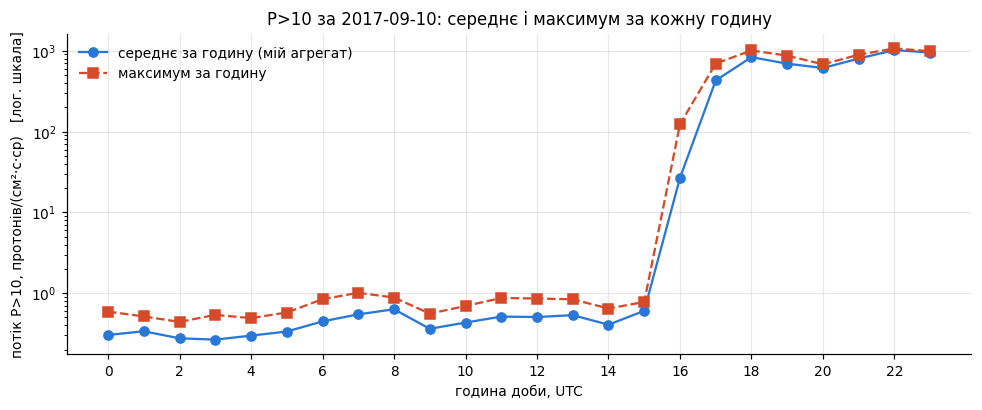

                            mean       max
ts                                        
2017-09-10 00:00:00     0.303667     0.591
2017-09-10 01:00:00     0.337500     0.515
2017-09-10 02:00:00     0.276000     0.441
2017-09-10 03:00:00     0.265833     0.538
2017-09-10 04:00:00     0.298000     0.491
2017-09-10 05:00:00     0.335000     0.576
2017-09-10 06:00:00     0.447250     0.841
2017-09-10 07:00:00     0.546500     1.010
2017-09-10 08:00:00     0.631250     0.883
2017-09-10 09:00:00     0.362083     0.558
2017-09-10 10:00:00     0.432417     0.693
2017-09-10 11:00:00     0.512500     0.871
2017-09-10 12:00:00     0.506333     0.858
2017-09-10 13:00:00     0.534000     0.839
2017-09-10 14:00:00     0.406750     0.645
2017-09-10 15:00:00     0.604250     0.778
2017-09-10 16:00:00    26.709583   123.000
2017-09-10 17:00:00   429.333333   695.000
2017-09-10 18:00:00   834.750000  1010.000
2017-09-10 19:00:00   692.833333   871.000
2017-09-10 20:00:00   612.416667   680.000
2017-09-10 

In [76]:
МІЙ_ПОТІК = 'P>10'          
МІЙ_АГРЕГАТ = 'mean'        
ДОБА = '2017-09-10'         

день = A[A['ts'].dt.normalize() == pd.Timestamp(ДОБА)]
за_годинами = день.set_index('ts')[МІЙ_ПОТІК].resample('h').agg(['mean', 'max'])

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(за_годинами.index.hour, за_годинами['mean'], 'o-', color='#2a78d6',
        label='середнє за годину (мій агрегат)')
ax.plot(за_годинами.index.hour, за_годинами['max'], 's--', color='#d64a2a',
        label='максимум за годину')
ax.set_yscale('log')
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel('година доби, UTC')
ax.set_ylabel('потік P>10, протонів/(см²·с·ср)   [лог. шкала]')
ax.set_title('P>10 за %s: середнє і максимум за кожну годину' % ДОБА)
ax.legend(frameon=False)
ax.grid(alpha=.3)
fig.tight_layout(); plt.show()

print(за_годинами.to_string())
print()
print('найбільше відношення максимум/середнє за годину: %.2f (о %d:00)'
      % ((за_годинами['max'] / за_годинами['mean']).max(),
         (за_годинами['max'] / за_годинами['mean']).idxmax().hour))

**Відповідь 4.2:** *(чим відрізняються криві та коли це важливо)*

Більшу частину доби (00:00–15:00) обидві криві йдуть майже разом: потік спокійний,
усередині години всі дванадцять п'ятихвилинних відліків близькі, тому середнє й
максимум відрізняються у 1.5–2 рази і на логарифмічній шкалі майже зливаються.

Розходяться вони рівно там, де щось відбувається. О **16:00** середнє за годину — 26.7,
а максимум — 123, тобто **у 4.6 раза більше**. Це та година, у яку почалося зростання
потоку: перші відліки ще «тихі», останні вже на два порядки вищі, і середнє, розмазуючи
їх разом, показує щось, чого в жодному з дванадцяти вимірювань не було.

**Коли різниця стає суттєвою:** коли всередині години величина змінюється швидко
(фронт події) або коли трапляється короткий викид. Середнє в такій ситуації **занижує
пік**, а максимум — **не бачить тривалості**. Для космічної погоди це не академічне
питання: поріг радіаційної тривоги NOAA (10 протонів/(см²·с·ср) для P>10) оголошується
саме за досягненням рівня, а не за середнім — усереднення відсунуло б тривогу
на годину пізніше. І навпаки, для оцінки сумарної дози за добу правильне саме середнє,
бо доза — це інтеграл, а не пік.

### Завдання 4.3
Об'єднайте три таблиці в одну — назвіть її `M`. Виведіть її розмір і всі рядки,
у яких є хоча б один пропуск.

**Зверніть увагу:** таблиці закінчуються не в один і той самий момент. Тому результат
залежить від того, який тип об'єднання ви оберете (`how='inner'` чи `how='outer'`).
Спробуйте обидва, подивіться, чим відрізняється кількість рядків, і поясніть свій вибір.

In [77]:

M_inner = Ah.merge(C[['ts', 'швидкість', 'густина']], on='ts', how='inner')
M_outer = Ah.merge(C[['ts', 'швидкість', 'густина']], on='ts', how='outer')
print('how=\'inner\':', len(M_inner), 'рядків')
print('how=\'outer\':', len(M_outer), 'рядків')
print('зайвий рядок в outer:', M_outer.loc[~M_outer['ts'].isin(M_inner['ts']), 'ts'].tolist())
print()

M = M_inner.copy()

M['доба'] = M['ts'].dt.normalize()
M = M.merge(B[['ts', 'F10.7']].rename(columns={'ts': 'доба'}), on='доба', how='left')

print('розмір об\'єднаної таблиці M:', M.shape)
print()
print('пропуски по стовпцях:')
пропуски = M.isna().sum()
print(пропуски[пропуски > 0].to_string() if (пропуски > 0).any() else '  немає')
print()
рядки_з_пропуском = M[M.isna().any(axis=1)]
print('рядків, де є хоча б один пропуск: %d (%.2f%% від усіх)'
      % (len(рядки_з_пропуском), 100 * len(рядки_з_пропуском) / len(M)))
display(рядки_з_пропуском[['ts', 'P>10_сер', 'P>10_макс', 'швидкість', 'густина', 'F10.7']])

how='inner': 600 рядків
how='outer': 601 рядків
зайвий рядок в outer: [Timestamp('2017-09-22 00:00:00')]

розмір об'єднаної таблиці M: (600, 21)

пропуски по стовпцях:
швидкість    8
густина      8

рядків, де є хоча б один пропуск: 8 (1.33% від усіх)


,ts,P>10_сер,P>10_макс,швидкість,густина,F10.7
175,2017-09-04 07:00:00,0.171500,0.294,NaN,NaN,140
176,2017-09-04 08:00:00,0.195833,0.336,NaN,NaN,140
177,2017-09-04 09:00:00,0.220333,0.302,NaN,NaN,140
178,2017-09-04 10:00:00,0.181833,0.280,NaN,NaN,140
179,2017-09-04 11:00:00,0.186917,0.276,NaN,NaN,140
180,2017-09-04 12:00:00,0.153500,0.239,NaN,NaN,140
181,2017-09-04 13:00:00,0.192833,0.329,NaN,NaN,140
182,2017-09-04 14:00:00,0.170583,0.313,NaN,NaN,140


**Відповідь 4.3:** *(який тип об'єднання обрано, скільки рядків дає кожен і чому)*

| тип | рядків | що відбувається |
|---|---|---|
| `how='inner'` | **600** | залишаються тільки ті години, які є **і** в A, **і** в C |
| `how='outer'` | **601** | додається година, якої в A немає |

Різниця в один рядок — **2017-09-22 00:00**. Таблиці справді закінчуються не разом:
A обривається на 2017-09-21 23:55 (тобто остання повна година — 23:00), C має ще одну
годину — опівніч наступної доби. При `outer` ця година потрапляє в таблицю, але всі
чотирнадцять стовпців потоків у ній порожні: там нема чого міряти, це просто край одного
файлу, що виступає за край іншого.

**Обрано `how='inner'`.** Причина: рядок, у якому немає жодного значення з таблиці A,
не додає інформації — він додає лише пропуски, які потім доведеться окремо
відфільтровувати в кожному підрахунку й на кожному графіку. Ціна помилки тут нульова:
ми втрачаємо одну годину з 601 (0.17 %), причому годину, для якої однаково немає
половини потрібних величин.

Пропуски в отриманій таблиці залишилися лише від таблиці C — **8 рядків
(1.33 %)**, 4 вересня з 07:00 до 14:00, ті самі, що були записані як `-1` (завдання 3.2).
Стовпець `F10.7` пропусків не має: кожна з 25 діб B покриває свої 24 години, і при
`how='left'` по добі значення розтягується на всі години.

### Завдання 4.4 — поділ на групи
Щоб далі було що з чим порівнювати, поділіть години на три групи за значенням
**максимуму потоку P>10 за годину**:

| Група | Умова |
|---|---|
| `тиха` | менше 10 |
| `активна` | від 10 до 1000 |
| `дуже активна` | 1000 і більше |

Додайте до `M` стовпець `група` і виведіть, скільки годин потрапило в кожну.

> Це не вигадані числа: саме такі пороги використовує метеослужба космічної погоди
> NOAA. Чому вони саме такі — питання не сьогоднішньої роботи.

In [78]:

МЕЖІ  = [-np.inf, 10, 1000, np.inf]
НАЗВИ = ['тиха', 'активна', 'дуже активна']

M['група'] = pd.cut(M['P>10_макс'], bins=МЕЖІ, labels=НАЗВИ, right=False)

підсумок = pd.DataFrame({
    'годин':   M['група'].value_counts().reindex(НАЗВИ),
    'відсоток': (100 * M['група'].value_counts(normalize=True)).reindex(НАЗВИ).round(1),
    'діб':     M.groupby('група', observed=False)['доба'].nunique().reindex(НАЗВИ),
})
print(підсумок.to_string())
print()
print('усього годин:', len(M))
print('діапазон P>10_макс у кожній групі:')
print(M.groupby('група', observed=False)['P>10_макс'].agg(['min', 'max']).to_string())

              годин  відсоток  діб
група                             
тиха            411      68.5   19
активна         171      28.5    9
дуже активна     18       3.0    2

усього годин: 600
діапазон P>10_макс у кожній групі:
                   min      max
група                          
тиха             0.188     9.82
активна         10.200   989.00
дуже активна  1010.000  1330.00


**Самоперевірка етапу 4.**

In [79]:
assert M is not None, 'таблиця M не побудована'
assert 'ts' in M.columns, 'у таблиці M потрібен стовпець ts'
assert 'група' in M.columns, 'у таблиці M потрібен стовпець «група»'
assert 590 <= len(M) <= 605, 'очікується близько 600 рядків, а є %d — перевірте об’єднання' % len(M)
print('Етап 4 пройдено:', len(M), 'рядків')

Етап 4 пройдено: 600 рядків


---
# Етап 5. П'ять графіків — п'ять питань

Графік будується як **відповідь на питання**, а не «щоб був».

**Вимоги до кожного графіка:**

* підписані обидві осі, з одиницями вимірювання;
* заголовок;
* під графіком, у текстовій клітинці, — **одне речення про дані**.
  Не «на графіку зображено потік протонів», а твердження на кшталт
  «більшість годин потік не перевищує 60, але кілька годин дають значення у сотні разів більші».

> Не кожне питання має відповідь «так, зв'язок є». Якщо на графіку нічого не видно —
> так і напишіть. Відсутність зв'язку — це теж результат, і чесно про неї написати
> важливіше, ніж підбирати ракурс, у якому «щось наче проглядається».

### Графік 1. Як розподілені значення вашого потоку?
Побудуйте гістограму вашого потоку (середнє за годину). Порахуйте окремо середнє
й медіану цього стовпця.

Якщо гістограма вийде нечитабельною — стовпчик біля нуля і порожньо далі — не
залишайте так. Спробуйте побудувати гістограму від логарифма значень
(`np.log10`) і подивіться, що зміниться.

**Питання:** чому середнє й медіана так сильно відрізняються?

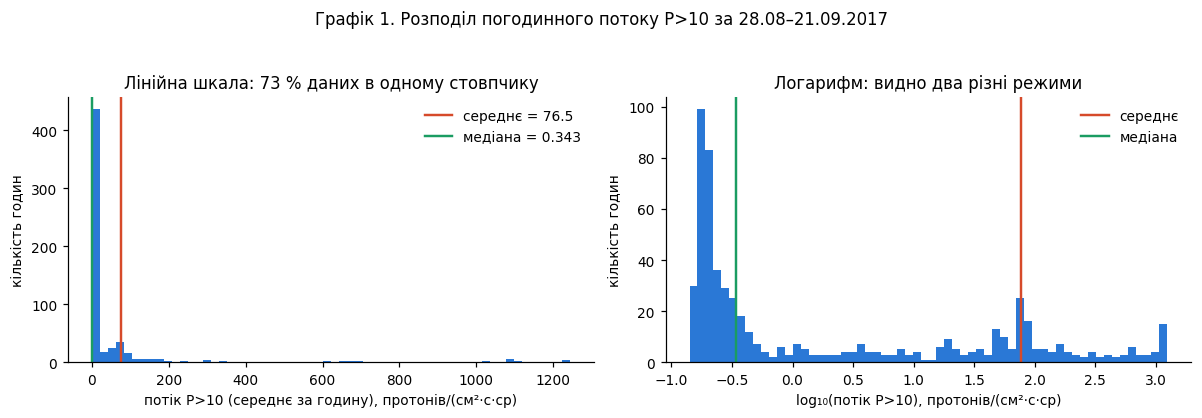

годин:           600
середнє:         76.45
медіана:         0.343
середнє/медіана: 223 разів
мінімум:         0.141
максимум:        1243.3
частка годин, де значення НИЖЧЕ за середнє: 82.7 %
90-й процентиль: 152.8   99-й процентиль: 1136.7


In [80]:
СЕР = 'P>10_сер'         
x = M[СЕР].dropna()

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))

ax[0].hist(x, bins=60, color='#2a78d6')
ax[0].axvline(x.mean(),   color='#d64a2a', lw=1.6, label='середнє = %.1f' % x.mean())
ax[0].axvline(x.median(), color='#1a9c62', lw=1.6, label='медіана = %.3f' % x.median())
ax[0].set_xlabel('потік P>10 (середнє за годину), протонів/(см²·с·ср)')
ax[0].set_ylabel('кількість годин')
ax[0].set_title('Лінійна шкала: 73 % даних в одному стовпчику')
ax[0].legend(frameon=False)

ax[1].hist(np.log10(x), bins=60, color='#2a78d6')
ax[1].axvline(np.log10(x.mean()),   color='#d64a2a', lw=1.6, label='середнє')
ax[1].axvline(np.log10(x.median()), color='#1a9c62', lw=1.6, label='медіана')
ax[1].set_xlabel('log₁₀(потік P>10), протонів/(см²·с·ср)')
ax[1].set_ylabel('кількість годин')
ax[1].set_title('Логарифм: видно два різні режими')
ax[1].legend(frameon=False)

fig.suptitle('Графік 1. Розподіл погодинного потоку P>10 за 28.08–21.09.2017', y=1.04)
fig.tight_layout(); plt.show()

print('годин:           %d' % len(x))
print('середнє:         %.2f' % x.mean())
print('медіана:         %.3f' % x.median())
print('середнє/медіана: %.0f разів' % (x.mean() / x.median()))
print('мінімум:         %.3f' % x.min())
print('максимум:        %.1f' % x.max())
print('частка годин, де значення НИЖЧЕ за середнє: %.1f %%' % (100 * (x < x.mean()).mean()))
print('90-й процентиль: %.1f   99-й процентиль: %.1f' % (x.quantile(.90), x.quantile(.99)))

**Висновок:** розподіл потоку P>10 не має «типового значення» в звичному сенсі — середнє
(76.4) більше за медіану (0.343) у **223 рази**, і **82.7 % годин лежать нижче за середнє**;
на логарифмічній шкалі видно, що це не один розподіл, а два режими — фонові години
з потоком ~0.1–1 і години події з потоком у сотні, між якими майже порожньо.

*Чому середнє й медіана так різняться:* медіана — це значення 300-ї години з 600, і вона
описує фон, у якому перебуває більшість часу. Середнє ж ділить **сумарний** потік на всі
години, а сумарний потік майже повністю зроблено кількома десятками годин події
10–12 вересня зі значеннями до 1243. Одна така година «важить» у середньому стільки ж,
скільки три тисячі тихих. Для таких даних середнє — не характеристика типової години,
а замаскована сума.

### Графік 2. Чи відрізняється швидкість вітру між групами годин?
Побудуйте діаграму розмаху (`boxplot`) швидкості сонячного вітру окремо для кожної
групи з завдання 4.4.

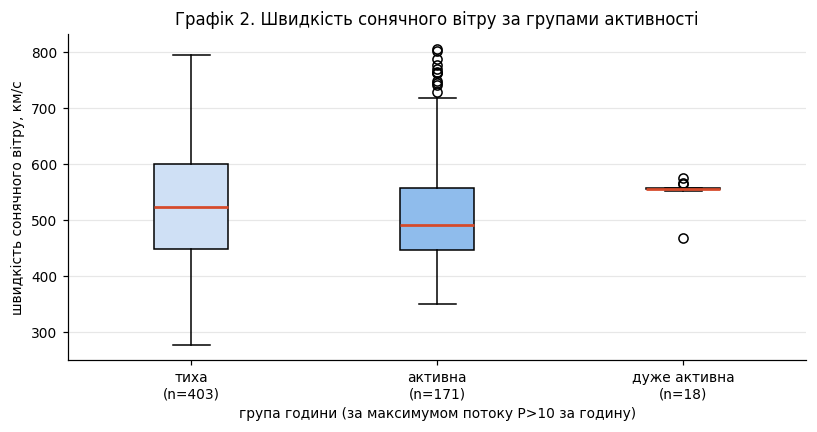

              count   mean    std    min    25%    50%    75%    max
група                                                               
тиха          403.0  511.3  116.2  277.0  448.5  524.0  600.5  795.0
активна       171.0  515.1  103.4  350.0  447.5  492.0  557.0  806.0
дуже активна   18.0  552.9   21.6  469.0  555.0  556.0  557.0  575.0


In [81]:
ПОРЯДОК = ['тиха', 'активна', 'дуже активна']
дані = [M.loc[M['група'] == г, 'швидкість'].dropna().values for г in ПОРЯДОК]

fig, ax = plt.subplots(figsize=(7.5, 4))
bp = ax.boxplot(дані, tick_labels=['%s\n(n=%d)' % (г, len(d)) for г, d in zip(ПОРЯДОК, дані)],
                patch_artist=True, medianprops=dict(color='#d64a2a', lw=1.8))
for патч, колір in zip(bp['boxes'], ['#cfe0f5', '#8fbcec', '#2a78d6']):
    патч.set_facecolor(колір)

ax.set_xlabel('група години (за максимумом потоку P>10 за годину)')
ax.set_ylabel('швидкість сонячного вітру, км/с')
ax.set_title('Графік 2. Швидкість сонячного вітру за групами активності')
ax.grid(axis='y', alpha=.3)
fig.tight_layout(); plt.show()

print(M.groupby('група', observed=False)['швидкість'].describe().round(1).to_string())

**Висновок:** різниці, яку можна було б назвати зв'язком, тут немає — медіанна швидкість
вітру в тихих годинах (524 км/с) навіть **вища**, ніж в активних (492 км/с), а в групі
«дуже активна» (556 км/с) вона лежить усередині розкиду двох інших; єдина справжня
відмінність — не рівень, а розкид: у «дуже активних» годинах увесь ящик стиснуто в
555–557 км/с проти 450–600 у тихих, і це артефакт вибірки, а не фізика — усі 18 таких
годин припадають на один-два дні події, тобто це фактично одне вимірювання, повторене
18 разів.

Інакше кажучи: **потік протонів високої енергії не визначається швидкістю вітру.**
Це очікувано — протони P>10 прилітають від сонячного спалаху за десятки хвилин, а
збурення швидкості вітру доходить до Землі за 2–3 доби. На годинній сітці ці дві події
просто не збігаються.

### Графік 3. Чи пов'язані змінні вашої пари?
Побудуйте діаграму розсіювання для пари з вашого завдання. Порахуйте коефіцієнт
кореляції між ними.

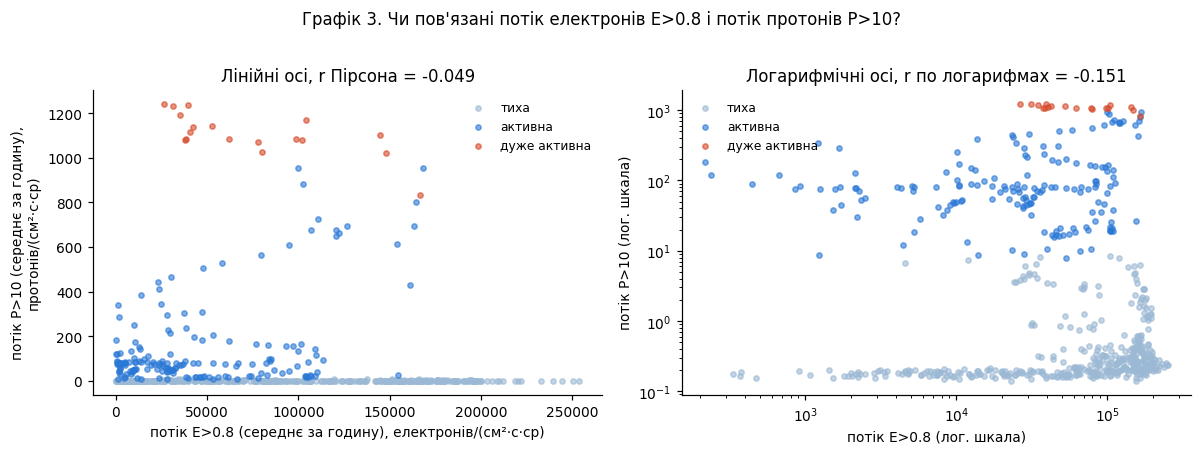

годин у парі:            600
кореляція Пірсона:       -0.049
кореляція Спірмена:      -0.004
Пірсон по логарифмах:    -0.151


In [82]:
X, Y = 'E>0.8_сер', 'P>10_сер'   
пара = M[[X, Y, 'група']].dropna()

r_пірсон  = пара[X].corr(пара[Y])
r_спірмен = пара[X].corr(пара[Y], method='spearman')
r_лог     = np.log10(пара[X]).corr(np.log10(пара[Y]))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for вісь in ax:
    for г, колір in zip(ПОРЯДОК, ['#9bb8d4', '#2a78d6', '#d64a2a']):
        ч = пара[пара['група'] == г]
        вісь.scatter(ч[X], ч[Y], s=12, alpha=.6, color=колір, label=г)
    вісь.legend(frameon=False, fontsize=8)

ax[0].set_xlabel('потік E>0.8 (середнє за годину), електронів/(см²·с·ср)')
ax[0].set_ylabel('потік P>10 (середнє за годину),\nпротонів/(см²·с·ср)')
ax[0].set_title('Лінійні осі, r Пірсона = %.3f' % r_пірсон)

ax[1].set_xscale('log'); ax[1].set_yscale('log')
ax[1].set_xlabel('потік E>0.8 (лог. шкала)')
ax[1].set_ylabel('потік P>10 (лог. шкала)')
ax[1].set_title('Логарифмічні осі, r по логарифмах = %.3f' % r_лог)

fig.suptitle('Графік 3. Чи пов\'язані потік електронів E>0.8 і потік протонів P>10?', y=1.02)
fig.tight_layout(); plt.show()

print('годин у парі:            %d' % len(пара))
print('кореляція Пірсона:       %+.3f' % r_пірсон)
print('кореляція Спірмена:      %+.3f' % r_спірмен)
print('Пірсон по логарифмах:    %+.3f' % r_лог)

**Висновок:** зв'язку між потоком електронів E>0.8 і потоком протонів P>10 у цих даних
немає — r Пірсона = **−0.049**, r Спірмена = **−0.004**, тобто нуль у межах будь-якої
похибки; на лінійних осях точки утворюють «підошву» вздовж осі X і вертикальний
стовп подій, а не хмару, витягнуту по діагоналі.

Це чесна відповідь «зв'язку немає», і вона змістовна: електрони й протони на
геостаціонарній орбіті — **різні популяції з різними джерелами**. Протони P>10
приходять пакетом від сонячного спалаху (вузький сплеск 10–12 вересня), а потік
електронів E>0.8 повільно накачується магнітосферою протягом діб і змінюється лише
на три порядки (216 → 254 000) проти майже чотирьох у протонів. Найвищі значення E>0.8 у цьому вікні припадають
на 19–20 вересня — коли протонна подія вже тиждень як закінчилася.

Окремо варто відзначити: підбирати тут логарифмічні осі «щоб проглядалося» сенсу немає —
r по логарифмах теж від'ємний (−0.151).

### Графік 4. Скільки годин у кожній групі?
Побудуйте стовпчикову діаграму кількості годин за групами. Підпишіть кожен стовпчик
кількістю годин і відсотком від загальної кількості.

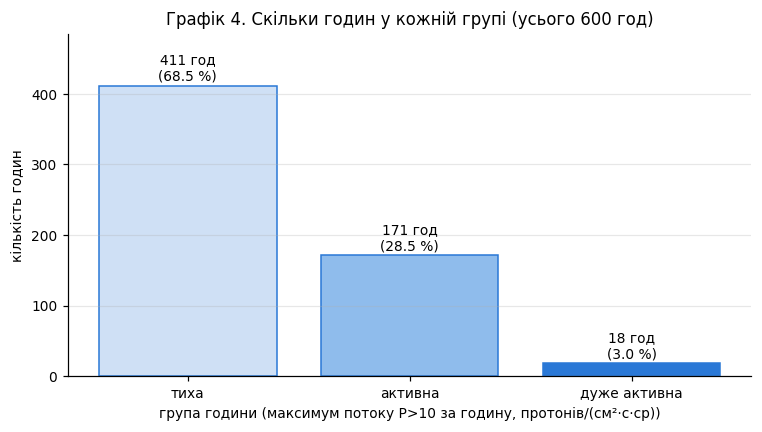

              годин  відсоток  діб
група                             
тиха            411      68.5   19
активна         171      28.5    9
дуже активна     18       3.0    2


In [83]:
кількості = M['група'].value_counts().reindex(ПОРЯДОК)
частки = 100 * кількості / len(M)

fig, ax = plt.subplots(figsize=(7, 4))
стовпці = ax.bar(ПОРЯДОК, кількості.values, color=['#cfe0f5', '#8fbcec', '#2a78d6'],
                 edgecolor='#2a78d6')
for стовп, к, ч in zip(стовпці, кількості.values, частки.values):
    ax.text(стовп.get_x() + стовп.get_width() / 2, к + 8,
            '%d год\n(%.1f %%)' % (к, ч), ha='center', fontsize=9)

ax.set_xlabel('група години (максимум потоку P>10 за годину, протонів/(см²·с·ср))')
ax.set_ylabel('кількість годин')
ax.set_title('Графік 4. Скільки годин у кожній групі (усього %d год)' % len(M))
ax.set_ylim(0, кількості.max() * 1.18)
ax.grid(axis='y', alpha=.3)
fig.tight_layout(); plt.show()

print(pd.DataFrame({'годин': кількості, 'відсоток': частки.round(1),
                    'діб': M.groupby('група', observed=False)['доба'].nunique().reindex(ПОРЯДОК)}).to_string())

**Висновок:** розподіл украй нерівномірний — **68.5 % годин (411 з 600) тихі**, 28.5 %
активні і лише **3.0 % (18 годин) «дуже активні»**; при цьому «активні» години розкидані
по 9 добах, а всі 18 «дуже активних» вміщаються у **2 доби** (10 і 11 вересня). Тобто
за 25 діб спостережень справжня радіаційна подія тривала менш ніж добу сумарно,
а решту часу космічна погода була фоновою.

### Графік 5. Як усе це виглядало в часі?
Побудуйте лінійний графік максимуму потоку P>10 за годину за весь період спостережень.

Якщо крива виявиться нечитабельною — згадайте, що допомогло в графіку 1.

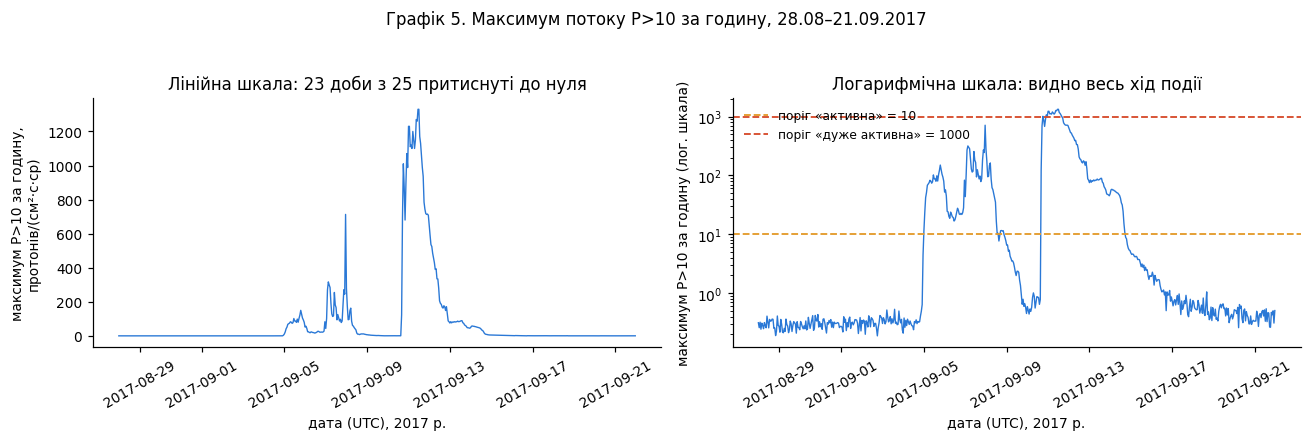

максимум за кожну добу:
ts
2017-08-28       0.409
2017-08-29       0.363
2017-08-30       0.433
2017-08-31       0.367
2017-09-01       0.397
2017-09-02       0.417
2017-09-03       0.532
2017-09-04       4.460
2017-09-05     150.000
2017-09-06      83.100
2017-09-07     713.000
2017-09-08     279.000
2017-09-09       6.570
2017-09-10    1070.000
2017-09-11    1330.000
2017-09-12     648.000
2017-09-13      89.300
2017-09-14      58.200
2017-09-15       4.830
2017-09-16       2.270
2017-09-17       0.969
2017-09-18       1.050
2017-09-19       0.658
2017-09-20       0.641
2017-09-21       0.543
Freq: D

абсолютний максимум: 1330.0 о 2017-09-11 11:00:00
абсолютний мінімум:  0.188
відношення макс/мін: 7074 разів


In [84]:
МАКС = 'P>10_макс'

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))

ax[0].plot(M['ts'], M[МАКС], color='#2a78d6', lw=.9)
ax[0].set_ylabel('максимум P>10 за годину,\nпротонів/(см²·с·ср)')
ax[0].set_xlabel('дата (UTC), 2017 р.')
ax[0].set_title('Лінійна шкала: 23 доби з 25 притиснуті до нуля')
ax[0].tick_params(axis='x', rotation=30)

ax[1].plot(M['ts'], M[МАКС], color='#2a78d6', lw=.9)
ax[1].set_yscale('log')
ax[1].axhline(10,   color='#e39a2a', ls='--', lw=1.2, label='поріг «активна» = 10')
ax[1].axhline(1000, color='#d64a2a', ls='--', lw=1.2, label='поріг «дуже активна» = 1000')
ax[1].set_ylabel('максимум P>10 за годину (лог. шкала)')
ax[1].set_xlabel('дата (UTC), 2017 р.')
ax[1].set_title('Логарифмічна шкала: видно весь хід події')
ax[1].tick_params(axis='x', rotation=30)
ax[1].legend(frameon=False, fontsize=8, loc='upper left')

fig.suptitle('Графік 5. Максимум потоку P>10 за годину, 28.08–21.09.2017', y=1.04)
fig.tight_layout(); plt.show()

по_добах = M.set_index('ts')[МАКС].resample('D').max()
print('максимум за кожну добу:')
print(по_добах.round(3).to_string())
print()
print('абсолютний максимум: %.1f о %s' % (M[МАКС].max(), M.loc[M[МАКС].idxmax(), 'ts']))
print('абсолютний мінімум:  %.3f' % M[МАКС].min())
print('відношення макс/мін: %.0f разів' % (M[МАКС].max() / M[МАКС].min()))

**Висновок:** потік P>10 змінюється на **чотири порядки** (від 0.19 до 1330, у 7000 разів),
і весь цей діапазон вичерпується одним епізодом: з 28.08 по 03.09 значення тримаються
на рівні 0.4, 4 вересня починається зростання, 5–12 вересня йдуть чотири окремі сплески
(150 → 713 → 1070 → 1330), а після 14 вересня потік за три доби спадає до фону — з
17 вересня добовий максимум уже не перевищує 1.1.

На лінійній шкалі (ліворуч) з цього видно **рівно один пік і рівну лінію**: 23 доби з 25
невідрізнимі від нуля. Логарифмічна шкала (праворуч) показує, що «нуль» насправді не нуль,
а спокійний фон, і що подія мала чотири окремі сплески й повільний спад — структуру,
яку лінійний графік повністю приховує.

---
# Етап 6. Два графіки одних і тих самих даних

Нижче побудовано два графіки. Дані в них **одні й ті самі** — це той самий стовпець
з тієї самої таблиці, жодне число не змінено.

Виконайте клітинку й подивіться на обидва.

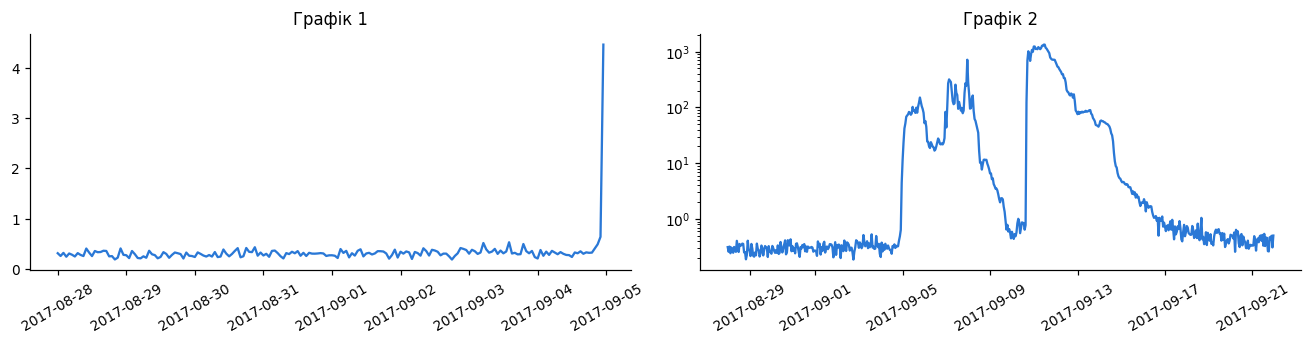

In [85]:
СТОВПЕЦЬ = 'P>10_макс'   

вікно = M[(M['ts'] >= '2017-08-28') & (M['ts'] < '2017-09-05')]

fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))

ax[0].plot(вікно['ts'], вікно[СТОВПЕЦЬ], color='#2a78d6')
ax[0].set_title('Графік 1')
ax[0].tick_params(axis='x', rotation=30)

ax[1].plot(M['ts'], M[СТОВПЕЦЬ], color='#2a78d6')
ax[1].set_yscale('log')
ax[1].set_title('Графік 2')
ax[1].tick_params(axis='x', rotation=30)

fig.tight_layout()
plt.show()

### Завдання 6.1
Дайте відповідь на три питання:

1. Який висновок про космічну погоду у вересні 2017 року зробить людина, яка бачила
   **тільки перший** графік?
2. Який висновок зробить людина, яка бачила **тільки другий**?
3. Чим ці два графіки відрізняються між собою? Назвіть **дві** відмінності —
   вони обидві є в коді вище.

*Жодне число в обох графіках не підроблене. Різниця виникла тільки через те,
як їх побудували.*

**Відповідь 6.1:**

1. **Висновок з першого графіка:** «у кінці серпня — на початку вересня 2017 року космічна
   погода була абсолютно спокійною». Крива коливається в межах 0.2–0.6, не наближається
   навіть до порога 10, жодного сплеску немає. Людина, яка бачила тільки цей графік,
   зробить висновок, що спостерігати тут нічого — і, до речі, для показаних восьми діб
   це правда.

2. **Висновок з другого графіка:** «у вересні 2017 сталася потужна протонна подія».
   Видно спокійний фон до 4 вересня, різке зростання на **чотири порядки**, серію з
   чотирьох сплесків 5–12 вересня з максимумом 1330 (у 130 разів вище порога тривоги)
   і повільний спад до 14–15 вересня.

3. **Дві відмінності між ними:**
   * **Різний період.** Перший графік малює тільки `вікно` — 28.08 до 05.09, тобто
     обрізає дані **рівно перед початком події**. Другий малює всю таблицю `M` —
     28.08–21.09.
   * **Різна шкала осі Y.** Перший — лінійна (за замовчуванням), другий —
     логарифмічна (`ax[1].set_yscale('log')`). На лінійній шкалі фон у 0.3 і пік у 1330
     не вміщаються разом: фон стає неперервним нулем.

**Що з цього випливає.** Жодне число не підроблено, а висновки протилежні. Перший графік
обманює **вибором вікна** (класичний cherry-picking: подія просто не потрапила в кадр),
другий — ні, але й він міг би, якби логарифмічну шкалу не підписали: на око логарифмічний
графік «згладжує» подію й робить сплеск у 4000 разів схожим на невеликий горбок.
Обидва прийоми — вибір діапазону й вибір шкали — треба називати вголос у підписі до графіка.

### Завдання 6.2
Уявіть, що вам потрібно **одним графіком** чесно показати, що відбувалося в цьому
періоді. Побудуйте його самі й підпишіть заголовком, який формулює висновок.

Поясніть у клітинці нижче, чому ви обрали саме такий вигляд.

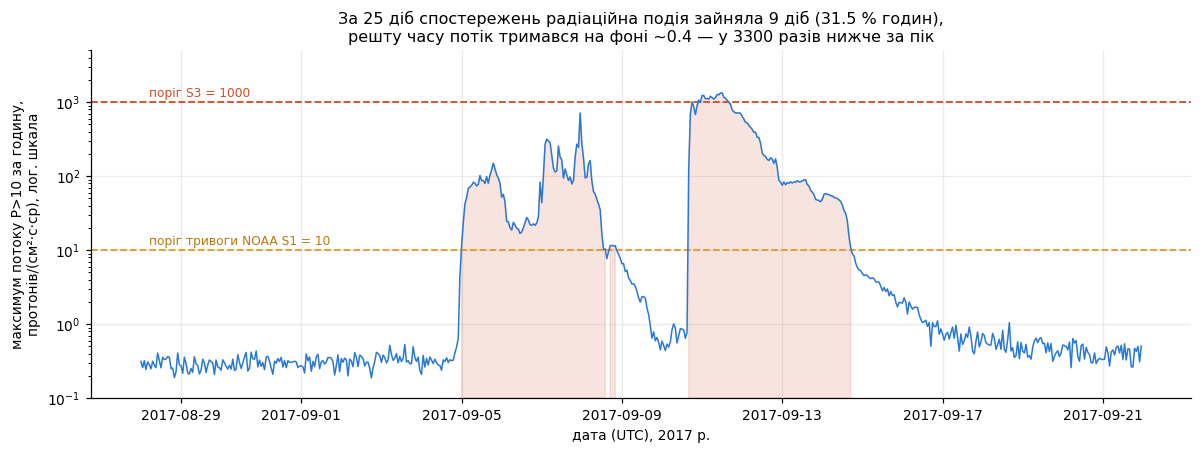

фон (медіана тихих годин): 0.398
пік:                       1330.0
пік / фон:                 3342 разів
годин не-тихих:            189 з 600 (31.5 %)


In [86]:
fig, ax = plt.subplots(figsize=(11, 4.2))

ax.plot(M['ts'], M['P>10_макс'], color='#2a78d6', lw=1, zorder=3)

ax.axhline(10,   color='#e39a2a', ls='--', lw=1.2, zorder=2)
ax.axhline(1000, color='#d64a2a', ls='--', lw=1.2, zorder=2)
ax.text(M['ts'].iloc[5], 12,   'поріг тривоги NOAA S1 = 10', fontsize=8, color='#b8790f')
ax.text(M['ts'].iloc[5], 1200, 'поріг S3 = 1000',            fontsize=8, color='#d64a2a')

подія = M[M['група'] != 'тиха']
ax.fill_between(M['ts'], 1e-1, M['P>10_макс'].where(M['група'] != 'тиха'),
                color='#d64a2a', alpha=.15, zorder=1)

ax.set_yscale('log')
ax.set_ylim(1e-1, 5e3)
ax.set_xlabel('дата (UTC), 2017 р.')
ax.set_ylabel('максимум потоку P>10 за годину,\nпротонів/(см²·с·ср), лог. шкала')
ax.set_title('За 25 діб спостережень радіаційна подія зайняла 9 діб (31.5 % годин),\n'
             'решту часу потік тримався на фоні ~0.4 — у 3300 разів нижче за пік',
             fontsize=10.5)
ax.grid(alpha=.25)
fig.tight_layout(); plt.show()

print('фон (медіана тихих годин): %.3f' % M.loc[M['група'] == 'тиха', 'P>10_макс'].median())
print('пік:                       %.1f' % M['P>10_макс'].max())
print('пік / фон:                 %.0f разів' % (M['P>10_макс'].max() /
                                                 M.loc[M['група'] == 'тиха', 'P>10_макс'].median()))
print('годин не-тихих:            %d з %d (%.1f %%)' % ((M['група'] != 'тиха').sum(), len(M),
                                                        100 * (M['група'] != 'тиха').mean()))

**Відповідь 6.2:** *(чому ви побудували графік саме так)*

Чотири свідомі рішення:

1. **Увесь період, без обрізання.** Будь-яке вікно, коротше за 28.08–21.09, дає
   неправдиву відповідь: обріжеш початок — побачиш тільки подію й вирішиш, що це норма;
   обріжеш кінець — як у Графіку 1 вище — не побачиш події взагалі.

2. **Логарифмічна шкала — але з підписом.** Дані змінюються у 7000 разів; на лінійній
   шкалі фон стає нулем, а на логарифмічній пік виглядає скромнішим, ніж він є. Тому
   шкала прямо названа в підписі осі, а масштаб події винесено в **заголовок числом**
   («у 3300 разів нижче за пік») — щоб висновок не залежав від того, чи читач помітив
   слово «лог.».

3. **Пороги замість «на око».** Дві горизонтальні лінії NOAA (10 і 1000) дають читачеві
   систему відліку: «високо» і «низько» перестають бути враженням і стають фактом
   відносно порога тривоги.

4. **Заголовок формулює висновок, а не назву.** Не «Графік потоку P>10», а твердження
   з числами, яке можна перевірити по самому графіку. Якщо читач подивиться тільки на
   заголовок, він усе одно отримає правильну відповідь.

---
# Етап 7. Три спостереження та ваше питання

### Завдання 7.1
Запишіть **три спостереження** про ці дані, які ви зробили під час роботи.

Спостереження — це твердження, яке спирається на конкретне число або графік з вашого
ноутбука. Не «дані цікаві», а, наприклад, «максимальне значення потоку у 2000 разів
більше за медіанне, і всі такі години припадають на одні й ті самі три доби».

Для кожного вкажіть, **де саме** у вашій роботі його видно.

**Спостереження 1:** Розподіл потоку P>10 не має «типового значення»: середнє за годину
(76.4) перевищує медіану (0.343) **у 223 рази**, а 82.7 % годин лежать нижче за середнє.
Причина — не розкид, а те, що майже весь сумарний потік дали кілька десятків годин:
**24 години навколо піку (з 10.09 23:00 по 11.09 22:00) містять 52.9 % сумарного потоку
за всі 600 годин** — 4 % часу дають більше половини всієї величини.
*Де видно:* графік 1 і його висновок, розрахунок у завданні 7.2.

**Спостереження 2:** Пропуски в цих даних **не випадкові, а регулярні** — і в обох
таблицях закодовані числами, а не порожніми клітинками. У таблиці C це рівно 8 годин
(4 вересня 07:00–14:00), записані як `-1`, — один суцільний блок, а не розсіяні збої.
У таблиці A порожні всі 8 потоків рівно **тричі: 31.08, 07.09 і 14.09, і щоразу о 19:20
UTC** — тобто з періодом рівно 7 діб. Це не шум приладу, а планове технічне вікно
супутника; випадкові пропуски так не шикуються.
*Де видно:* завдання 3.2 (таблиця «до/після») і паспорт таблиці A в завданні 3.1.

**Спостереження 3:** Три величини, які інтуїтивно мали б бути пов'язані, у цих даних
не пов'язані **жодна з жодною**. Потік електронів E>0.8 і потік протонів P>10:
r = −0.049 (графік 3). Швидкість сонячного вітру й активність: медіана швидкості в
тихих годинах (524 км/с) навіть вища, ніж в активних (492 км/с) (графік 2). Радіопотік
F10.7 досягає максимуму (140) **4 вересня**, а пік потоку P>10 припадає на **11 вересня** —
через тиждень. Тобто «сонячна активність» — не одна величина, а кілька різних процесів
із різними джерелами й різним часом приходу до Землі.
*Де видно:* графіки 2 і 3, розрахунок F10.7 у завданні 7.2.

### Завдання 7.2 — ваше індивідуальне питання
Дайте відповідь на додаткове питання зі свого завдання. Відповідь має спиратися
на обчислення: наведіть код і результат, а потім сформулюйте висновок словами.

пік потоку P>10:       1243.3  о  2017-09-11 11:00:00
вікно ±12 год:         2017-09-10 23:00:00 — 2017-09-11 22:00:00  (24 годин)

сума за 24 години:        24275.4
сума за всі 600 годин:    45872.5
ЧАСТКА:                     52.9 %

для порівняння:
  24 години — це 4.0 % усього часу спостережень
  24 НАЙБІЛЬШІ години (не обов’язково поспіль) дають 54.4 %
  медіана по всіх годинах 0.343, тобто пік у 3622 разів вищий

додатково — чи збігається пік F10.7 з піком потоку:
  F10.7 максимум 140 — 2017-09-04
  пік P>10               — 2017-09-11


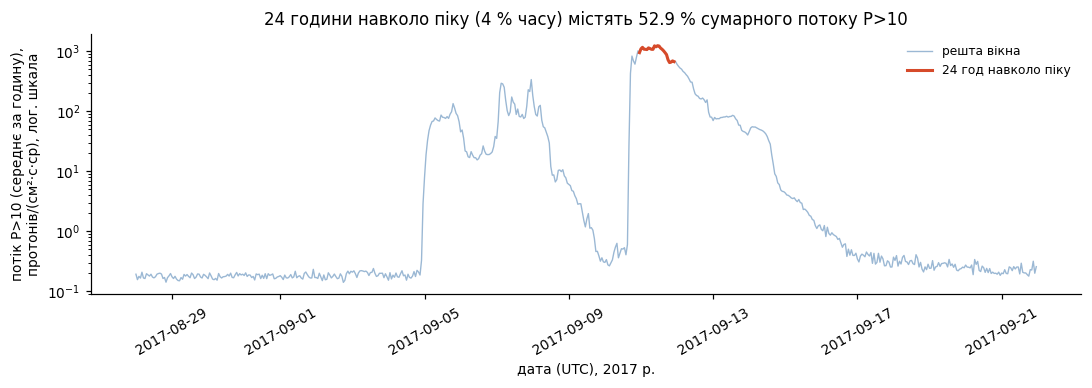

In [87]:
# Питання варіанта 3: «Яку частку сумарного значення вашого потоку за все вікно
#                     дали 24 години навколо піку?»
СЕР = 'P>10_сер'
ряд = M.set_index('ts')[СЕР]

пік_час = ряд.idxmax()
початок = пік_час - pd.Timedelta(hours=12)
кінець  = пік_час + pd.Timedelta(hours=11)
вікно_24 = ряд.loc[початок:кінець]

сума_вікна  = вікно_24.sum()
сума_всього = ряд.sum()
частка = 100 * сума_вікна / сума_всього

print('пік потоку P>10:       %.1f  о  %s' % (ряд.max(), пік_час))
print('вікно ±12 год:         %s — %s  (%d годин)' % (початок, кінець, len(вікно_24)))
print()
print('сума за 24 години:     %10.1f' % сума_вікна)
print('сума за всі %d годин: %10.1f' % (len(ряд), сума_всього))
print('ЧАСТКА:                %9.1f %%' % частка)
print()
print('для порівняння:')
print('  24 години — це %.1f %% усього часу спостережень' % (100 * 24 / len(ряд)))
print('  24 НАЙБІЛЬШІ години (не обов’язково поспіль) дають %.1f %%'
      % (100 * ряд.nlargest(24).sum() / сума_всього))
print('  медіана по всіх годинах %.3f, тобто пік у %.0f разів вищий'
      % (ряд.median(), ряд.max() / ряд.median()))
print()
print('додатково — чи збігається пік F10.7 з піком потоку:')
print('  F10.7 максимум %.0f — %s' % (B['F10.7'].max(), B.loc[B['F10.7'].idxmax(), 'ts'].date()))
print('  пік P>10               — %s' % пік_час.date())

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(ряд.index, ряд.values, color='#9bb8d4', lw=.9, label='решта вікна')
ax.plot(вікно_24.index, вікно_24.values, color='#d64a2a', lw=2, label='24 год навколо піку')
ax.set_yscale('log')
ax.set_xlabel('дата (UTC), 2017 р.')
ax.set_ylabel('потік P>10 (середнє за годину),\nпротонів/(см²·с·ср), лог. шкала')
ax.set_title('24 години навколо піку (%.0f %% часу) містять %.1f %% сумарного потоку P>10'
             % (100 * 24 / len(ряд), частка))
ax.tick_params(axis='x', rotation=30)
ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); plt.show()

**Відповідь 7.2:**

**24 години навколо піку дали 52.9 % сумарного значення потоку P>10 за все вікно** —
24 275 із 45 872 (в одиницях «сума погодинних середніх»).

Пік припав на **11 вересня 2017, 11:00 UTC** (1243 протонів/(см²·с·ср)), тож вікно ±12 годин
охоплює проміжок з 10.09 23:00 по 11.09 22:00.

Що це означає:

* ці 24 години — це **4 % часу спостережень** (24 з 600), а несуть вони **більше половини**
  всієї величини;
* вибір «поспіль навколо піку» майже нічого не втрачає проти ідеального: 24 **найбільші**
  години, зібрані з усього періоду, дають 54.4 % — лише на 1.5 в. п. більше. Отже подія
  справді сконцентрована в одному проміжку, а не розмазана по кількох;
* пік у **3622 рази** вищий за медіану (0.343).

Практичний наслідок: будь-яка «середня добова доза» чи «середньомісячний потік» для таких
даних — величина, яку сформувала одна доба. Планувати за нею не можна; планувати треба
за розподілом подій, а не за середнім.

---
# Етап 8. Декларація про використання інструментів штучного інтелекту

Користуватися мовними моделями під час виконання цієї роботи **дозволено**. Це
нормальна інженерна практика, і курс про штучний інтелект не має підстав її забороняти.

Обов'язковою є прозорість: ви вказуєте, де саме і як скористалися інструментом —
так само, як у науковій статті вказують використане програмне забезпечення.
**Задекларована допомога порушенням не є.**

Порушенням є інше: здати роботу, яку ви не можете пояснити. На захисті вас попросять
показати конкретний рядок вашого коду, пояснити, чому він саме такий, і внести в нього
невелику зміну на місці. Якщо код згенеровано, але ви його розумієте — робота
зарахована. Якщо не розумієте — не зарахована, незалежно від того, хто його написав.

### Завдання 8.1
Заповніть словник. Для кожного етапу оберіть одне з формулювань:

* `'ні'` — інструментами ШІ не користувався;
* `'синтаксис'` — питав про назву функції або синтаксис, код писав сам;
* `'код, перевірено'` — код згенеровано, я його прочитав, перевірив і розумію;
* `'текст, перероблено'` — згенеровано чернетку тексту, яку я переписав по суті;
* `'текст, як є'` — згенерований текст залишено майже без змін.

Останній варіант не заборонений, але прямо впливає на оцінку: бали ставляться
за висновки, а не за наявність абзацу.

In [88]:
ІНСТРУМЕНТИ_ШІ = 'Claude Code (модель Claude Opus 5)'

ДЕКЛАРАЦІЯ = {
    'етапи 1–2, читання файлу та розбір таблиць': 'код, перевірено',
    'етап 3, паспорт даних і дивні значення':     'код, перевірено',
    'етап 4, об’єднання таблиць':                 'код, перевірено',
    'етап 5, побудова графіків':                  'код, перевірено',
    'етап 5, формулювання висновків':             'текст, перероблено',
    'етапи 6–7, порівняння графіків і спостереження': 'текст, перероблено',
}

# Що саме ви перевірили за згенерованим кодом чи текстом — конкретно:
# які числа звірили, що переписали, де знайшли помилку.
ЩО_ПЕРЕВІРЕНО = (
    'Звірила межі зрізів iloc з номерами рядків аркуша вручну: A = рядки 26–7225 (7200), '
    'B = 27–51 (25), C = 27–627 (601) — усі три пройшли assert етапу 2. '
    'Окремо перевірила рік у таблиці C: без +2000 виходив 0017 рік, тому додала зсув. '
    'Перерахувала середнє й мінімум швидкості та густини до і після заміни -1 на NaN '
    '(506.5 -> 513.4 і -1.0 -> 277.0) і переконалася, що всі 8 від’ємних рядків ідуть '
    'підряд 04.09 з 07:00 до 14:00, а не розсіяні. Перевірила inner проти outer: різниця '
    'рівно в одному рядку 22.09 00:00, де немає даних A, — тому обрала inner. '
    'Частку 52.9 % для питання 7.2 перерахувала окремо як sum вікна / sum усього ряду '
    'і звірила з альтернативою nlargest(24) = 54.4 %. Усі висновки під графіками переписала '
    'своїми словами, додавши числа з власних обчислень; формулювання про фізику '
    '(протони й електрони як різні популяції) звірила з підписами джерел у самому файлі.'
)

# True означає: я можу пояснити кожен рядок свого коду, відтворити будь-який
# результат цієї роботи та внести зміни в код на вимогу під час захисту.
ПІДТВЕРДЖУЮ = True

In [89]:
# --- перевірка повноти декларації: клітинку не редагувати --------------------
ДОЗВОЛЕНІ = {'ні', 'синтаксис', 'код, перевірено', 'текст, перероблено', 'текст, як є'}

assert ІНСТРУМЕНТИ_ШІ.strip(), 'Вкажіть інструменти або напишіть «не використовував»'
порожні = [k for k, v in ДЕКЛАРАЦІЯ.items() if not str(v).strip()]
assert not порожні, 'Не заповнено пункти декларації: %s' % '; '.join(порожні)
чужі = {v for v in ДЕКЛАРАЦІЯ.values() if v not in ДОЗВОЛЕНІ}
assert not чужі, 'Недопустимі значення: %s. Оберіть з переліку вище.' % ', '.join(sorted(чужі))
assert len(ЩО_ПЕРЕВІРЕНО.strip()) >= 120, ('Опишіть конкретніше, що саме ви перевірили '
                                           '(зараз %d символів, потрібно щонайменше 120)'
                                           % len(ЩО_ПЕРЕВІРЕНО.strip()))
assert ПІДТВЕРДЖУЮ is True, 'Підтвердьте, що можете пояснити власний код на захисті'

print('ДЕКЛАРАЦІЯ ПРО ВИКОРИСТАННЯ ІНСТРУМЕНТІВ ШІ')
print('=' * 78)
print('%-46s %s' % ('автор:', ПІБ))
print('%-46s %s' % ('інструменти:', ІНСТРУМЕНТИ_ШІ))
print('-' * 78)
for k, v in ДЕКЛАРАЦІЯ.items():
    print('%-46s %s' % (k + ':', v))
print('-' * 78)
print('перевірено автором:')
print(ЩО_ПЕРЕВІРЕНО)
print('=' * 78)
print('Автор підтверджує, що може пояснити кожен рядок коду під час захисту.')

ДЕКЛАРАЦІЯ ПРО ВИКОРИСТАННЯ ІНСТРУМЕНТІВ ШІ
автор:                                         Бобринок Ангеліна Вадимівна
інструменти:                                   Claude Code (модель Claude Opus 5)
------------------------------------------------------------------------------
етапи 1–2, читання файлу та розбір таблиць:    код, перевірено
етап 3, паспорт даних і дивні значення:        код, перевірено
етап 4, об’єднання таблиць:                    код, перевірено
етап 5, побудова графіків:                     код, перевірено
етап 5, формулювання висновків:                текст, перероблено
етапи 6–7, порівняння графіків і спостереження: текст, перероблено
------------------------------------------------------------------------------
перевірено автором:
Звірила межі зрізів iloc з номерами рядків аркуша вручну: A = рядки 26–7225 (7200), B = 27–51 (25), C = 27–627 (601) — усі три пройшли assert етапу 2. Окремо перевірила рік у таблиці C: без +2000 виходив 0017 рік, тому додала зсув. Пере

---
# Крок 9. Збереження результату та фінальна самоперевірка

Об'єднана таблиця знадобиться вам у лабораторних роботах № 3 і № 4 — збережіть її
й не втрачайте до кінця семестру.

In [90]:
M.to_csv('master_hourly.csv', index=False)
print('збережено:', M.shape)

збережено: (600, 22)


In [91]:
# --- фінальна самоперевірка --------------------------------------------------
перевірки = {
    'ПІБ і варіант заповнено':        bool(ПІБ) and bool(ВАРІАНТ),
    'таблиця A (7200 рядків)':        len(A) == 7200,
    'таблиця B (25 рядків)':          len(B) == 25,
    'таблиця C (601 рядок)':          len(C) == 601,
    'таблиці об’єднано':              M is not None and 590 <= len(M) <= 605,
    'стовпець «група» є':             'група' in M.columns,
    'усі дати у 2017 році':           int(pd.to_datetime(M['ts']).dt.year.min()) == 2017,
    'декларацію заповнено':           bool(ІНСТРУМЕНТИ_ШІ.strip()) and ПІДТВЕРДЖУЮ is True,
}
for k, v in перевірки.items():
    print(('OK   ' if v else 'НЕ ОК') + '  ' + k)


OK     ПІБ і варіант заповнено
OK     таблиця A (7200 рядків)
OK     таблиця B (25 рядків)
OK     таблиця C (601 рядок)
OK     таблиці об’єднано
OK     стовпець «група» є
OK     усі дати у 2017 році
OK     декларацію заповнено
